**Analyse exploratoire:**
Profils de production et relations avec la météo, sur les heures de jour uniquement.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/dataset_jour.csv", index_col="DATE_TIME", parse_dates=True)
df["heure"] = df.index.hour
df["date"] = df.index.date
df.head()

,AC_POWER_TOTAL,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,heure,date
DATE_TIME,,,,,,
2020-05-15 06:15:00,593.338690,24.011635,22.353459,0.022282,6,2020-05-15
2020-05-15 06:30:00,1480.194643,23.976731,22.893282,0.049410,6,2020-05-15
2020-05-15 06:45:00,2790.448214,24.218990,24.442444,0.095394,6,2020-05-15
2020-05-15 07:00:00,4052.662143,24.537398,27.185653,0.141940,7,2020-05-15
2020-05-15 07:15:00,4368.722619,24.815960,28.888478,0.154713,7,2020-05-15


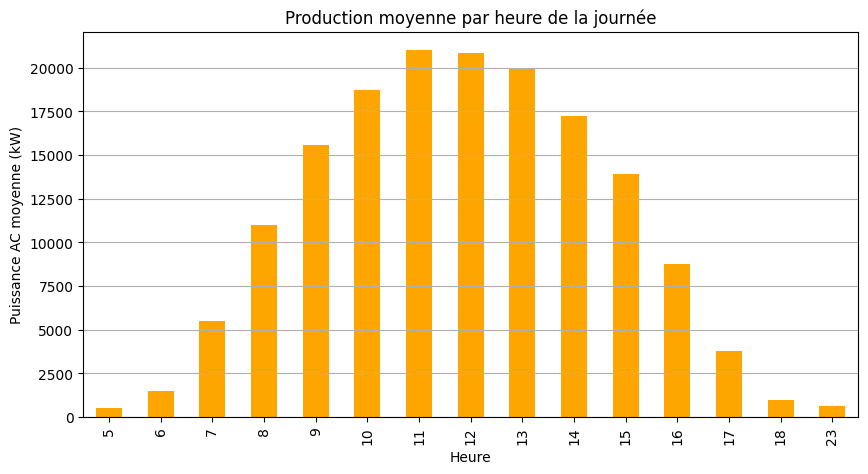

In [2]:
profil = df.groupby("heure")["AC_POWER_TOTAL"].mean()

plt.figure(figsize=(10, 5))
profil.plot(kind="bar", color="orange")
plt.title("Production moyenne par heure de la journée")
plt.xlabel("Heure")
plt.ylabel("Puissance AC moyenne (kW)")
plt.grid(axis="y")
plt.show()

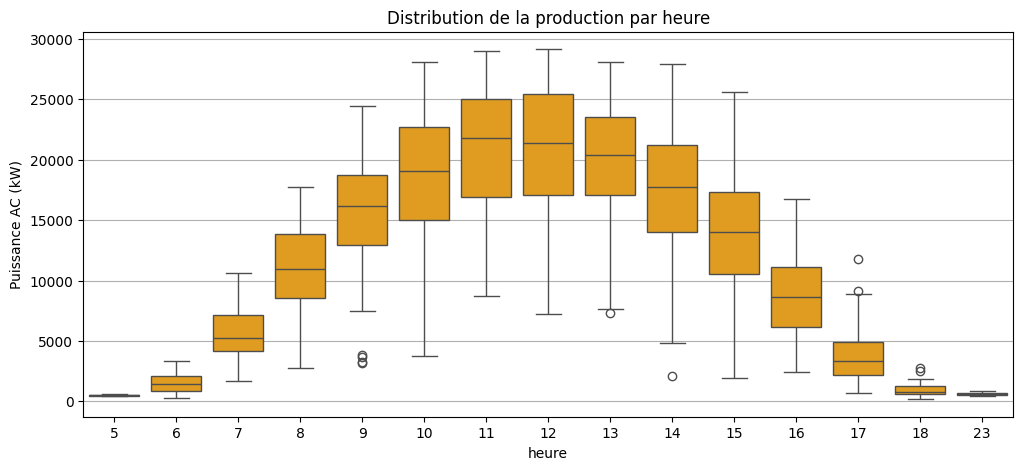

In [3]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="heure", y="AC_POWER_TOTAL", color="orange")
plt.title("Distribution de la production par heure")
plt.ylabel("Puissance AC (kW)")
plt.grid(axis="y")
plt.show()

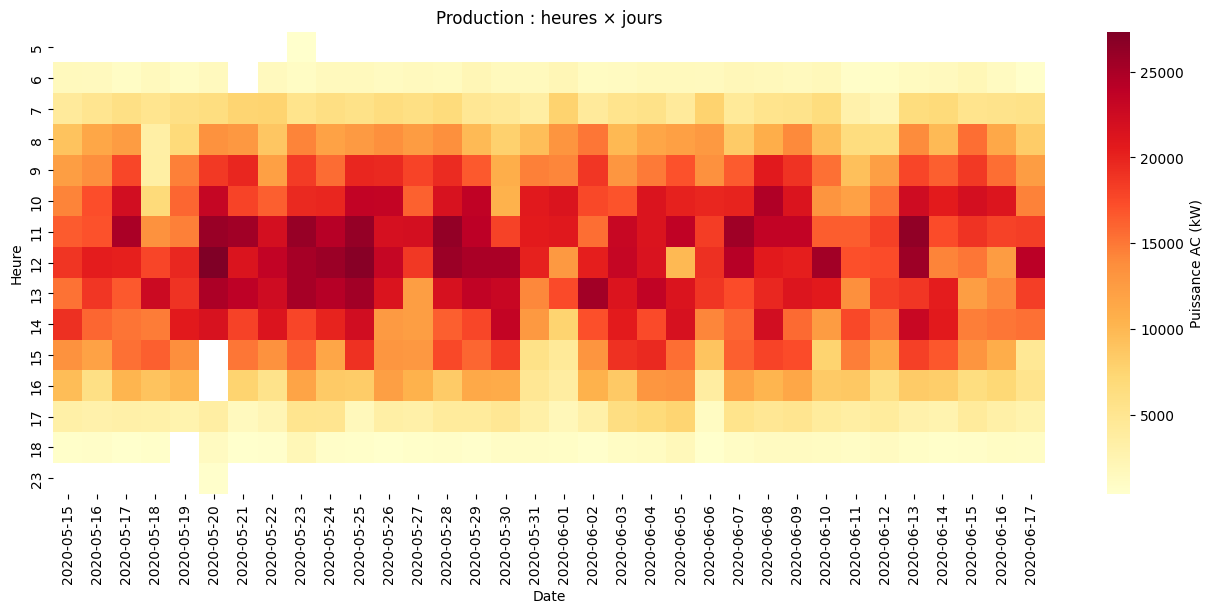

In [4]:
pivot = df.pivot_table(index="heure", columns="date", values="AC_POWER_TOTAL")

plt.figure(figsize=(16, 6))
sns.heatmap(pivot, cmap="YlOrRd", cbar_kws={"label": "Puissance AC (kW)"})
plt.title("Production : heures × jours")
plt.xlabel("Date")
plt.ylabel("Heure")
plt.show()

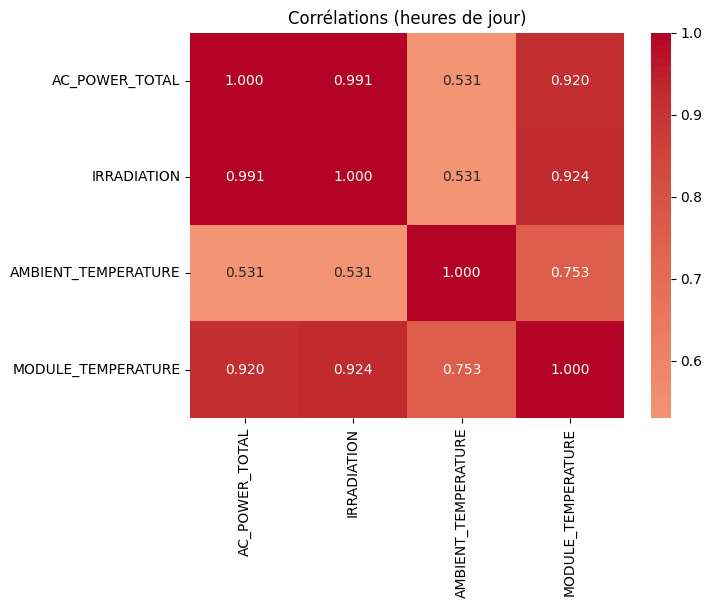

In [5]:
# Matrice de corrélation sur les heures de jour uniquement
corr = df[["AC_POWER_TOTAL", "IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE"]].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".3f")
plt.title("Corrélations (heures de jour)")
plt.show()

- Irradiance : 0,991 même sans la nuit → relation réelle
- Température ambiante : 0,72 → 0,53 sans la nuit (corrélation surtout due au cycle jour/nuit)
- Température module corrélée à 0,92 avec la production et à 0,92 avec l'irradiance → colinéarité

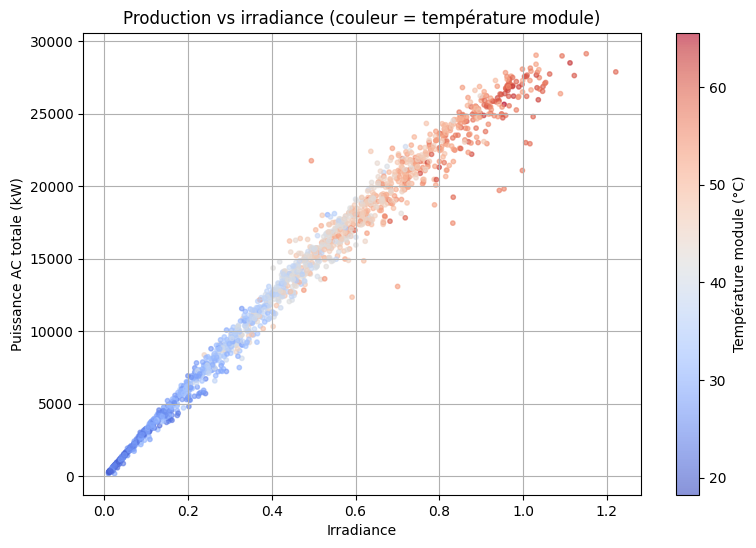

In [6]:
# Nuage de points irradiance vs production
plt.figure(figsize=(9, 6))
plt.scatter(df["IRRADIATION"], df["AC_POWER_TOTAL"],
            c=df["MODULE_TEMPERATURE"], cmap="coolwarm", s=10, alpha=0.6)
plt.colorbar(label="Température module (°C)")
plt.xlabel("Irradiance")
plt.ylabel("Puissance AC totale (kW)")
plt.title("Production vs irradiance (couleur = température module)")
plt.grid(True)
plt.show()

- Relation quasi linéaire jusqu'à environ 0,8 d'irradiance, puis plafonnement vers 29 000 kW
- Causes probables : perte thermique (modules à 55–65 °C, environ -0,4 %/°C) et écrêtage onduleur (ratio DC/AC > 1)
- → justifie un modèle non linéaire et la température module en variable